In [1]:
%load_ext autoreload
%autoreload 2

import math
import random
import matplotlib.pyplot as plt

import beam_python as bp

random.seed(2026)

GeV = 1.0
MeV = 0.001

M_pi = 139.57039 * MeV
M_mu = 105.65837 * MeV

In [2]:
print("Загружен файл:", bp.__file__)

p_star = bp.momentum_in_CM(M_pi, M_mu)

print("Импульс в системе покоя пиона:", p_star, "ГэВ")
print("То же в МэВ:", p_star / MeV)

Загружен файл: C:\Users\Anton\neutrino-modeling\beam_python.py
Импульс в системе покоя пиона: 0.02979214507351883 ГэВ
То же в МэВ: 29.792145073518828


In [3]:
direction = bp.random_direction()

print(direction)
print(sum(component**2 for component in direction))

(0.7327336817876673, 0.6804969033554488, 0.005031510462501165)
0.9999999999999998


In [4]:
norm_squared = sum(component**2 for component in direction)

assert abs(norm_squared - 1) < 1e-12

In [5]:
p4 = (5.0, (1.0, 2.0, 3.0))

transformed = bp.lorentz_boost(0.6, p4)
restored = bp.lorentz_boost(-0.6, transformed)

print("Инвариант до:", bp.norm2(p4))
print("Инвариант после:", bp.norm2(transformed))
print("После обратного преобразования:", restored)

Инвариант до: 11.0
Инвариант после: 11.0
После обратного преобразования: (5.0, (1.0, 2.0, 3.0))


In [6]:
beam = bp.neutrino_beam(
    M_beam=M_pi,
    P_beam=10 * GeV,
    m_lepton=M_mu
)

print(next(beam))

(3.6716545779467347, (-0.02061792208195042, -0.0015344112226657839, 3.6715963676074796))


In [7]:
E_nu = []

for i in range(100_000):
    p4 = next(beam)
    E_nu.append(p4[0])

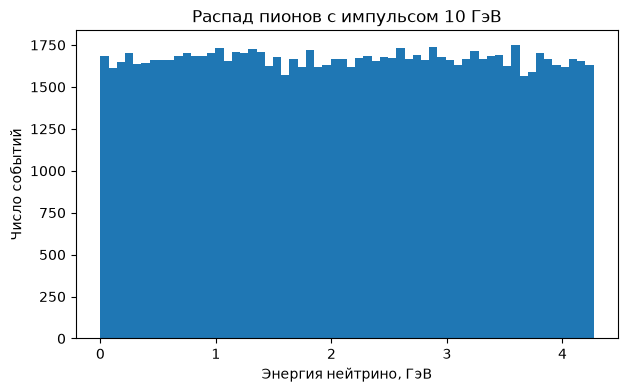

In [8]:
plt.figure(figsize=(7, 4))

plt.hist(E_nu, bins=60)

plt.xlabel("Энергия нейтрино, ГэВ")
plt.ylabel("Число событий")
plt.title("Распад пионов с импульсом 10 ГэВ")

plt.show()

In [9]:
from collections import defaultdict

data = defaultdict(list)

beam = bp.neutrino_beam_uniform(
    M_beam=M_pi,
    P_beam_max=10 * GeV,
    m_lepton=M_mu
)

In [10]:
%%time

N_samples = 1_000_000

for i in range(N_samples):
    p4_nu, P_parent = next(beam)

    E, (px, py, pz) = p4_nu

    cos_theta = max(-1.0, min(1.0, pz / E))
    theta = math.acos(cos_theta)

    data["E"].append(E)
    data["theta"].append(theta)
    data["P_parent"].append(P_parent)

CPU times: total: 3.52 s
Wall time: 3.58 s


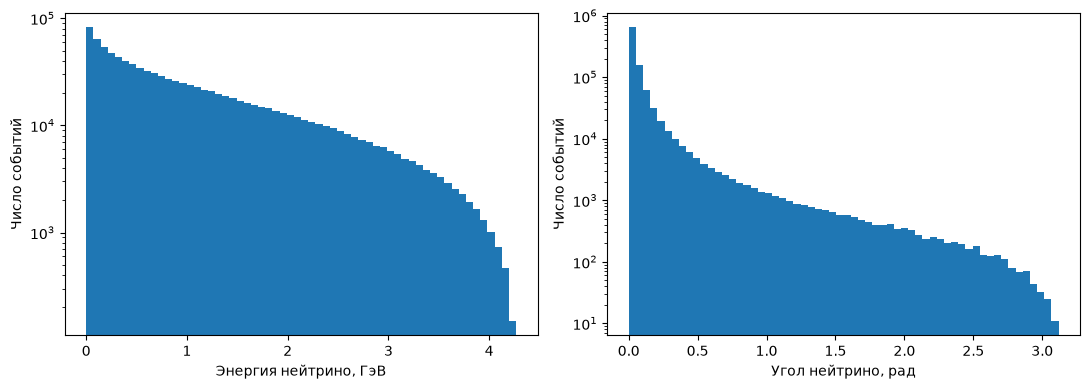

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(data["E"], bins=60)
axes[0].set_xlabel("Энергия нейтрино, ГэВ")
axes[0].set_ylabel("Число событий")
axes[0].set_yscale("log")

axes[1].hist(data["theta"], bins=60)
axes[1].set_xlabel("Угол нейтрино, рад")
axes[1].set_ylabel("Число событий")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

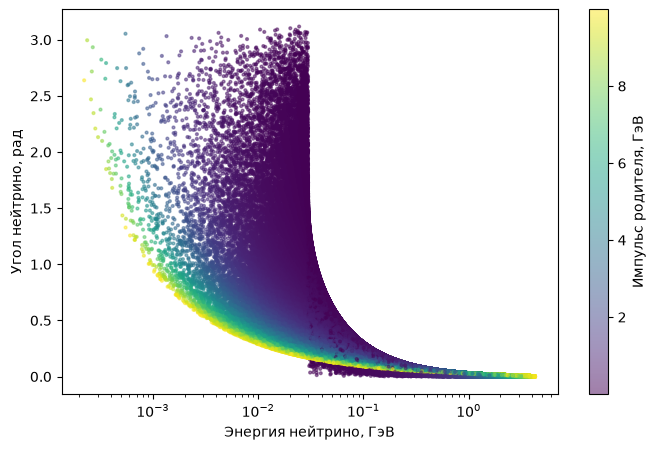

In [12]:
plt.figure(figsize=(8, 5))

sc = plt.scatter(
    data["E"],
    data["theta"],
    c=data["P_parent"],
    s=4,
    alpha=0.5
)

plt.xscale("log")
plt.xlabel("Энергия нейтрино, ГэВ")
plt.ylabel("Угол нейтрино, рад")

plt.colorbar(sc, label="Импульс родителя, ГэВ")

plt.show()

In [13]:
%%time

beam_for_timing = bp.neutrino_beam_uniform(
    M_pi, 10 * GeV, M_mu
)

for i in range(1_000_000):
    next(beam_for_timing)

CPU times: total: 2.67 s
Wall time: 2.68 s
